# Tiền xử lý Ames Housing & phòng tránh Data Leakage

Các bước: loại cột định danh → chia Train/Val/Test theo `Yr Sold` → kiểm toán NaN trên Train → kiểm tra dịch chuyển dữ liệu → xây Pipeline (chỉ fit trên Train) → bảng missing trước/sau → xuất dữ liệu.
Notebook dừng ở bước chuẩn bị đặc trưng, chưa huấn luyện mô hình.

## 1. Đọc dữ liệu, loại cột định danh

- `Order`, `PID` chỉ là mã định danh từng dòng, không mô tả căn nhà → loại bỏ.
- `MS SubClass` có kiểu số nhưng thực chất là **mã loại nhà** (20, 60, 120...). Phép so sánh lớn/nhỏ hay cộng trừ trên các mã này vô nghĩa (mã 60 không phải "gấp 3 lần" mã 20) → chuyển sang chuỗi để xử lý như biến phân loại.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = pd.read_csv("AmesHousing - AmesHousing.csv.csv")   # nếu dùng file Excel: pd.read_excel("AmesHousing.xlsx")
print("Kích thước ban đầu:", df.shape)

df = df.drop(columns=["Order", "PID"])
df["MS SubClass"] = df["MS SubClass"].astype(str)
print("Sau khi bỏ ID:", df.shape)

Kích thước ban đầu: (2930, 82)
Sau khi bỏ ID: (2930, 80)


## 2. Chia dữ liệu theo thời gian (không shuffle)

| Tập | Năm bán | Số giao dịch kỳ vọng |
|---|---|---:|
| Train | 2006–2008 | 1.941 |
| Validation | 2009 | 648 |
| Test | 2010 | 341 |

Dùng quá khứ để dự đoán tương lai, nên Validation/Test không được tham gia học bất kỳ tham số tiền xử lý nào. `SalePrice` được tách riêng làm nhãn `y`.

In [2]:
train_df = df[df["Yr Sold"].between(2006, 2008)]
val_df   = df[df["Yr Sold"] == 2009]
test_df  = df[df["Yr Sold"] == 2010]

X_train, y_train = train_df.drop(columns="SalePrice"), train_df["SalePrice"]
X_val,   y_val   = val_df.drop(columns="SalePrice"),   val_df["SalePrice"]
X_test,  y_test  = test_df.drop(columns="SalePrice"),  test_df["SalePrice"]

# Kiểm tra số dòng của từng tập
expected = {"Train": 1941, "Validation": 648, "Test": 341}
actual = {"Train": len(X_train), "Validation": len(X_val), "Test": len(X_test)}
row_check = pd.DataFrame({
    "Năm bán": ["2006–2008", "2009", "2010"],
    "Số dòng X": list(actual.values()),
    "Số dòng y": [len(y_train), len(y_val), len(y_test)],
    "Kỳ vọng": list(expected.values()),
}, index=expected.keys())
row_check["Khớp đề"] = row_check["Số dòng X"] == row_check["Kỳ vọng"]
row_check

,Năm bán,Số dòng X,Số dòng y,Kỳ vọng,Khớp đề
Train,2006–2008,1941,1941,1941,True
Validation,2009,648,648,648,True
Test,2010,341,341,341,True


In [3]:
# Xuất dữ liệu sau chia tách (chưa tiền xử lý)
os.makedirs("output", exist_ok=True)
for name, obj in {"X_train": X_train, "X_val": X_val, "X_test": X_test,
                  "y_train": y_train, "y_val": y_val, "y_test": y_test}.items():
    obj.to_csv(f"output/{name}.csv", index=False)

## 2.2. Kiểm toán dữ liệu thiếu (chỉ trên Train)

In [4]:
missing = pd.DataFrame({
    "Số lượng NaN": X_train.isna().sum(),
    "Tỷ lệ (%)": (X_train.isna().mean() * 100).round(2),
})
missing = missing[missing["Số lượng NaN"] > 0].sort_values("Tỷ lệ (%)", ascending=False)
missing

,Số lượng NaN,Tỷ lệ (%)
Pool QC,1928,99.33
Misc Feature,1878,96.75
Alley,1805,92.99
Fence,1576,81.20
Mas Vnr Type,1172,60.38
Fireplace Qu,940,48.43
Lot Frontage,321,16.54
Garage Qual,107,5.51
Garage Cond,107,5.51
Garage Yr Blt,107,5.51


### Quyết định giữ / bỏ / điền

| Nhóm | Cột | Quyết định | Lý do |
|---|---|---|---|
| Structural Missing | `Pool QC`, `Alley`, `Fence`, `Fireplace Qu`, `Garage Type`, `Bsmt Qual` | **Giữ**, điền `"None"` | NaN nghĩa là *căn nhà không có hồ bơi / hẻm / hàng rào / lò sưởi / garage / tầng hầm*, đây là thông tin thật. `Pool QC` thiếu tới ~99% nhưng vẫn giữ vì "None" vs "có hồ bơi" là tín hiệu giá nhà (ít mẫu nên mô hình sau này có thể bỏ nếu không hữu ích) |
| `Electrical` | `Electrical` | **Giữ**, điền mode (`most_frequent`) | Chỉ thiếu 1 mẫu, điền giá trị phổ biến nhất của Train. Đây là phương án xử lý thực dụng, không khẳng định đã chứng minh MCAR |
| `Lot Frontage` | `Lot Frontage` | **Giữ**, điền median + `add_indicator=True` | Thiếu 321/1.941 mẫu (16,54%): quá nhiều để bỏ dòng, median bền với outlier, cột indicator giữ lại tín hiệu "ô này ban đầu bị thiếu". Có thể đặt giả thuyết MAR nhưng không kết luận cơ chế thiếu chỉ từ tỷ lệ NaN |
| Số còn lại | `Garage Yr Blt`, `Mas Vnr Area`, `Bsmt ...`, `Garage Area`... | **Giữ**, điền median | Phương án baseline. Nếu muốn chính xác hơn: số liên quan garage/hầm điền 0 khi nhà không có garage/hầm |
| Phân loại còn lại | `Misc Feature`, `Mas Vnr Type`, `Garage Qual/Cond/Finish`, `Bsmt Cond/Exposure`, `BsmtFin Type 1/2` | **Giữ**, điền `"Missing"` | Giữ trạng thái "chưa biết", không khẳng định là không có tiện ích. Đề xuất nếu giữ lâu dài: `Misc Feature`, `Mas Vnr Type` (khi `Mas Vnr Area = 0`) và nhóm Garage/Bsmt điền `"None"` sau khi đối chiếu cột liên quan |

Không có cột nào bị **bỏ** ở bước này, ngoài `Order`, `PID` ở phần 1.

## 2.3. Kiểm tra dịch chuyển dữ liệu (Data Shift)

So sánh Train với Validation cho `Lot Area` (phân phối) và tỷ lệ thiếu của `Lot Frontage`. Đây chỉ là bước **quan sát**: kết quả không được dùng để học giá trị điền hay thay đổi bất kỳ thống kê nào đã fit.

          Train  Validation
count    1941.0       648.0
mean    10284.8      9953.8
std      7832.3      9052.5
min      1470.0      1300.0
25%      7420.0      7500.0
50%      9450.0      9432.0
75%     11631.0     11479.2
max    164660.0    215245.0

KS test Lot Area: statistic = 0.0279, p-value = 0.8326


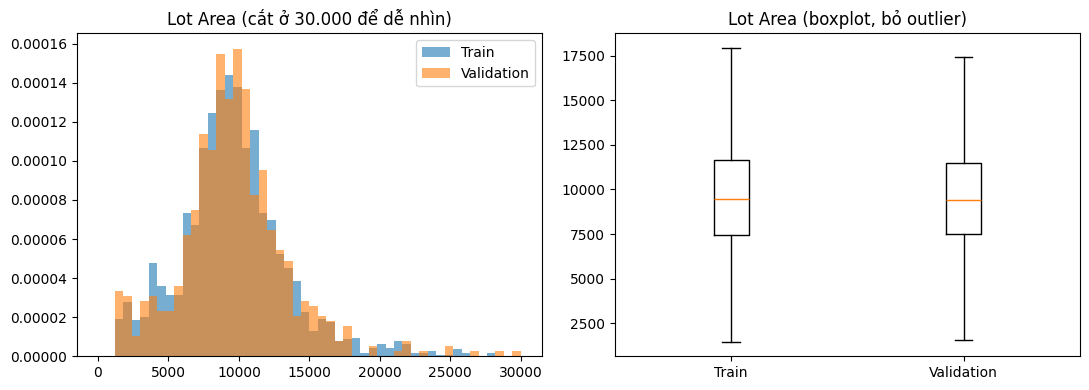

In [5]:
# --- Lot Area: so sánh phân phối Train vs Validation ---
la_train, la_val = X_train["Lot Area"], X_val["Lot Area"]

print(pd.DataFrame({"Train": la_train.describe(), "Validation": la_val.describe()}).round(1))

ks_stat, ks_p = ks_2samp(la_train, la_val)
print(f"\nKS test Lot Area: statistic = {ks_stat:.4f}, p-value = {ks_p:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(la_train, bins=50, range=(0, 30000), alpha=0.6, density=True, label="Train")
ax[0].hist(la_val, bins=50, range=(0, 30000), alpha=0.6, density=True, label="Validation")
ax[0].set_title("Lot Area (cắt ở 30.000 để dễ nhìn)"); ax[0].legend()
ax[1].boxplot([la_train, la_val], tick_labels=["Train", "Validation"], showfliers=False)
ax[1].set_title("Lot Area (boxplot, bỏ outlier)")
plt.tight_layout(); plt.show()

In [6]:
# --- Lot Frontage: so sánh tỷ lệ thiếu Train vs Validation ---
lf_rate = pd.DataFrame({
    "Số dòng": [len(X_train), len(X_val)],
    "Số NaN": [X_train["Lot Frontage"].isna().sum(), X_val["Lot Frontage"].isna().sum()],
}, index=["Train", "Validation"])
lf_rate["Tỷ lệ thiếu (%)"] = (lf_rate["Số NaN"] / lf_rate["Số dòng"] * 100).round(2)
print(lf_rate)

table = [[lf_rate.loc[s, "Số NaN"], lf_rate.loc[s, "Số dòng"] - lf_rate.loc[s, "Số NaN"]] for s in lf_rate.index]
chi2, chi_p, _, _ = chi2_contingency(table)
print(f"\nChi-square tỷ lệ thiếu Lot Frontage: p-value = {chi_p:.4f}")

print("\nKết luận:")
print("- Lot Area:", "phân phối KHÁC nhau (p < 0.05)" if ks_p < 0.05 else "chưa thấy khác biệt có ý nghĩa thống kê")
print("- Tỷ lệ thiếu Lot Frontage:", "KHÁC nhau (p < 0.05)" if chi_p < 0.05 else "chưa thấy khác biệt có ý nghĩa thống kê")

            Số dòng  Số NaN  Tỷ lệ thiếu (%)
Train          1941     321            16.54
Validation      648     118            18.21

Chi-square tỷ lệ thiếu Lot Frontage: p-value = 0.3567

Kết luận:
- Lot Area: chưa thấy khác biệt có ý nghĩa thống kê
- Tỷ lệ thiếu Lot Frontage: chưa thấy khác biệt có ý nghĩa thống kê


**Nhận xét:** đọc cùng lúc p-value, median và biểu đồ ở trên. Nếu cả hai p-value đều lớn (≥ 0,05) và hai phân phối chồng khít, chưa có dấu hiệu Data Shift đáng kể giữa Train và Validation, nên median học từ Train vẫn hợp lý để điền cho Validation/Test. Nếu p-value nhỏ, cần xem độ lớn chênh lệch (median, tỷ lệ thiếu) vì với cỡ mẫu vài trăm, khác biệt nhỏ vẫn có thể "có ý nghĩa thống kê". Dù kết quả thế nào, ta **không** sửa lại thống kê đã fit bằng dữ liệu Validation/Test, vì như vậy là Data Leakage.

## 3. Pipeline + ColumnTransformer

Mỗi nhóm cột có một Pipeline riêng. `handle_unknown="ignore"` giúp One-Hot không lỗi khi Val/Test có category mà Train chưa thấy.

In [7]:
structural_cols = ["Pool QC", "Alley", "Fence", "Fireplace Qu", "Garage Type", "Bsmt Qual"]
electrical_cols = ["Electrical"]
lot_cols = ["Lot Frontage"]

num_cols = [c for c in X_train.select_dtypes("number").columns if c not in lot_cols]
cat_cols = [c for c in X_train.select_dtypes(exclude="number").columns
            if c not in structural_cols + electrical_cols]

ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer([
    ("structural", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")), ("enc", ohe())]), structural_cols),
    ("electrical", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("enc", ohe())]), electrical_cols),
    ("lot_frontage", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), lot_cols),
    ("numeric", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("categorical", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")), ("enc", ohe())]), cat_cols),
])

## 4. Fit trên Train, chỉ transform Validation/Test

Đây là bước chống Data Leakage: median, mode, mean/std và danh mục One-Hot đều chỉ học từ Train.

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)   # fit + transform trên Train
X_val_processed   = preprocessor.transform(X_val)         # chỉ transform
X_test_processed  = preprocessor.transform(X_test)        # chỉ transform

print("Train:", X_train_processed.shape)
print("Val:  ", X_val_processed.shape)
print("Test: ", X_test_processed.shape)

Train: (1941, 332)
Val:   (648, 332)
Test:  (341, 332)


## 5. Bảng missing trước / sau xử lý

In [9]:
# Trước xử lý: số NaN từng cột (cột có NaN) ở cả 3 tập
before = pd.DataFrame({
    "Train": X_train.isna().sum(),
    "Validation": X_val.isna().sum(),
    "Test": X_test.isna().sum(),
})
before = before[before.sum(axis=1) > 0].sort_values("Train", ascending=False)
before

,Train,Validation,Test
Pool QC,1928,648,341
Misc Feature,1878,627,319
Alley,1805,606,321
Fence,1576,518,264
Mas Vnr Type,1172,383,220
Fireplace Qu,940,298,184
Lot Frontage,321,118,51
Garage Qual,107,29,23
Garage Cond,107,29,23
Garage Yr Blt,107,29,23


In [10]:
# Tổng hợp trước / sau
summary = pd.DataFrame({
    "Tổng ô NaN trước": [X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum()],
    "Số cột có NaN trước": [(X_train.isna().sum() > 0).sum(), (X_val.isna().sum() > 0).sum(), (X_test.isna().sum() > 0).sum()],
    "Tổng ô NaN sau": [pd.isna(X_train_processed).sum(), pd.isna(X_val_processed).sum(), pd.isna(X_test_processed).sum()],
    "Số đặc trưng sau": [X_train_processed.shape[1], X_val_processed.shape[1], X_test_processed.shape[1]],
}, index=["Train", "Validation", "Test"])
summary

,Tổng ô NaN trước,Số cột có NaN trước,Tổng ô NaN sau,Số đặc trưng sau
Train,10434,27,0,332
Validation,3463,18,0,332
Test,1852,18,0,332


In [11]:
# Xuất ma trận đặc trưng đã xử lý (có tên cột)
feature_names = preprocessor.get_feature_names_out()
pd.DataFrame(X_train_processed, columns=feature_names).to_csv("output/X_train_processed.csv", index=False)
pd.DataFrame(X_val_processed,   columns=feature_names).to_csv("output/X_val_processed.csv", index=False)
pd.DataFrame(X_test_processed,  columns=feature_names).to_csv("output/X_test_processed.csv", index=False)

## 6. Tổng kết

- Đã loại `Order`, `PID`; `MS SubClass` xử lý như biến phân loại.
- Chia theo thời gian: Train 2006–2008, Validation 2009, Test 2010; `y = SalePrice`; số dòng từng tập đã được kiểm tra ở bảng phần 2.
- Missing được kiểm toán chỉ trên Train; mọi cột được giữ, điền theo bảng quyết định ở phần 2.2.
- Đã so sánh Train/Validation về `Lot Area` và tỷ lệ thiếu `Lot Frontage` (phần 2.3); không dùng Validation/Test để học bất kỳ giá trị điền nào.
- Sau xử lý không còn NaN; kết quả lưu trong thư mục `output/`.